In [1]:
%load_ext autoreload
%autoreload 2

from typing import Type, Tuple
from pathlib import Path
import logging
import pytorch_lightning as pl
from omegaconf import OmegaConf, DictConfig
from oat.predictor_module.oat_predictor import OATPredictor
from oat.data_module.setup import setup_data_and_transform
from matplotlib import pyplot as plt
import torch

def load_checkpoint(predictor_cls: Type[pl.LightningModule], checkpoint_file_path: str)-> Tuple[pl.LightningModule, DictConfig]:
    """
    Load and return the Predictor and its config from a checkpoint file.
    
    predictor_cls is the class of the Predictor to load. 
    checkpoint_file_path is the path to the checkpoint file, not the folder.
    It is expected that the parent folder of this checkpoint contains, at the same 
    level as the checkpoint, a yaml file with the config used to train the model.
    """
    path = Path(checkpoint_file_path)
    checkpoint_folder = path.parent
    config_path = checkpoint_folder / "config.yaml"
    
    cfg = OmegaConf.load(config_path)
    
    predictor = predictor_cls.load_from_checkpoint(path)
    
    return predictor, cfg

## Load model

In [2]:
cfg_path = "/scratch/mch/cdonner/observation_assimilation_transformer/checkpoints/debugging/oat_training_20260224_job3955558/best-model-epoch=02-val_loss=-0.4826.ckpt"
#cfg_path = "/users/miccatta/s-ruc/observation_assimilation_transformer/checkpoints/lost_checkpoints/good_uninformed/best-model-epoch=26-val_loss=-1.1953.ckpt"
predictor, cfg = load_checkpoint(OATPredictor, cfg_path)
_ = predictor.eval()

/scratch/mch/cdonner/observation_assimilation_transformer/.venv/lib/python3.12/site-packages/lightning_fabric/utilities/cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
/scratch

## Load data

In [3]:
logger = logging.getLogger(__name__)
dataset, train_loader, val_loader, test_loader, input_transform, output_transform = setup_data_and_transform(cfg, logger)

Dataset /scratch/mch/fzanetta/data/anemoi/datasets/mch-co1e-an-archive-0p01-2019-2024-1h-v1-pl13.zarr has missing dates
Gathering dataset statistics: 100%|██████████| 128/128 [09:15<00:00,  4.34s/it]


In [64]:
from copy import deepcopy

batch = next(iter(test_loader))
batch_station = deepcopy(batch)
batch_station['query_data'] = {k: torch.concat([batch['query_data'][k], batch['observation_data'][k]], dim=1) for k in batch['query_data'].keys()}
prediction_station, prediction_pre_oat_station = predictor.predict_step(batch_station, 0,  return_pre_oat=True)

# Create query around station

In [137]:
batch_size = cfg.dataloader.batch_size
station_idx = 12
center_pos = batch['query_data']['coords'][0, station_idx]
center_geo = batch['query_data']['geo'][0, station_idx]
size = 40000 # in metres
step = 250 # in metres
extent = [[center_pos[0] - size / 2, center_pos[0] + size / 2], 
          [center_pos[1] - size / 2, center_pos[1] + size / 2]]
mesh = torch.meshgrid(torch.linspace(extent[0][0], extent[0][1], size // step),
                      torch.linspace(extent[1][0], extent[1][1], size // step))
mesh = torch.stack(mesh, dim=-1)
mesh_shape = mesh.shape
mesh_flattened = mesh.view(-1, 2)

query_mesh = dataset.get_query(mesh_flattened)
query_batch = {k: v[None].expand(batch_size, -1, *v.shape[1:]) for k, v in query_mesh.items()}
print(test_loader.dataset.station_info['eval'].iloc[station_idx])

station_name                                Binn
latitude                               46.367661
longitude                               8.192306
station_height                            1479.0
swiss_easting                     2657995.892616
swiss_northing                    1135420.846139
ASPECT_2000M_SIGRATIO1                178.687622
WE_DERIVATIVE_2000M_SIGRATIO1          -0.003231
TPI_2000M                            -164.874023
SN_DERIVATIVE_10000M_SIGRATIO1         -0.029355
dem                                  1485.398438
SN_DERIVATIVE_2000M_SIGRATIO1           0.141042
SLOPE_10000M_SIGRATIO1                  4.853341
ASPECT_10000M_SIGRATIO1               290.226044
SLOPE_2000M_SIGRATIO1                   8.030262
STD_2000M                             154.684896
STD_10000M                            386.821601
TPI_10000M                           -533.751465
WE_DERIVATIVE_10000M_SIGRATIO1          0.079674
station_type                       meteo_station
Name: BIN, dtype: ob

In [138]:
batch['query_data'] = query_batch
predictor.model.num_samples = 1000
prediction, predictions_pre_oat = predictor.predict_step(batch, 0, return_pre_oat=True)

: 

In [27]:
mean_pred_station = prediction_station.detach().mean(dim=-2).cpu().numpy()
mean_pred_station_pre_oat = predictions_pre_oat_station.detach().mean(dim=-2).cpu().numpy()
mean_pred_mesh = prediction.detach().mean(dim=-2).cpu().numpy().reshape(batch_size, *mesh_shape)
mean_pred_mesh_pre_oat = predictions_pre_oat.detach().mean(dim=-2).cpu().numpy().reshape(batch_size, *mesh_shape)

# Plot predictions

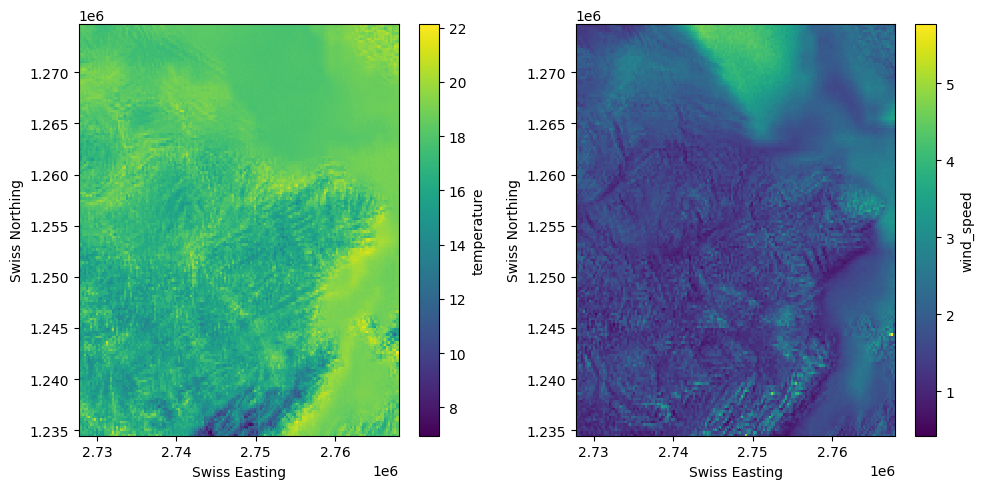

In [22]:
fig = plt.figure(figsize=(10, 5))
var_idx = 0
ax1 = fig.add_subplot(1, 2, 1)
im1 = ax1.pcolor(mesh[:, :, 0], mesh[:, :, 1], mean_pred_mesh[1, :, :, var_idx], shading='auto')
plt.colorbar(im1, label=predictor.output_var_names[var_idx])
ax1.set_xlabel("Swiss Easting")
ax1.set_ylabel("Swiss Northing")
var_idx = 1
ax2 = fig.add_subplot(1, 2, 2)
im2 = ax2.pcolor(mesh[:, :, 0], mesh[:, :, 1], mean_pred_mesh[0, :, :, var_idx], shading='auto')
plt.colorbar(im2, label=predictor.output_var_names[var_idx])
ax2.set_xlabel("Swiss Easting")
ax2.set_ylabel("Swiss Northing")
plt.tight_layout()

/tmp/ipykernel_6262/2519625103.py:30: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax3.scatter(batch_station['query_data']['coords'][0, :][:, 0], batch_station['query_data']['coords'][0, :][:, 1], c=[.8,.8,.8], marker='o', s=50, label='Eval Stations')


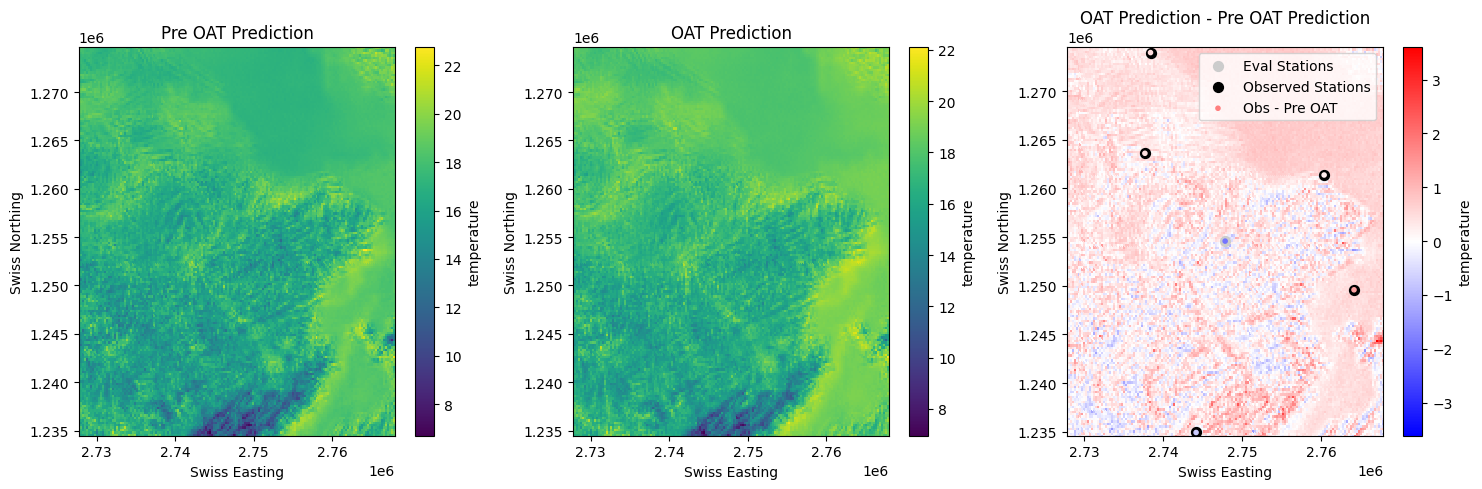

In [ ]:
var_idx = 0
fig = plt.figure(figsize=(15, 5))

ax1 = fig.add_subplot(1, 3, 1)
im1 = ax1.pcolor(mesh[:, :, 0], mesh[:, :, 1], mean_pred_mesh_pre_oat[1, :, :, var_idx], shading='auto')
plt.colorbar(im1, label=predictor.output_var_names[var_idx])
ax1.set_xlabel("Swiss Easting")
ax1.set_ylabel("Swiss Northing")
ax1.set_title("Pre OAT Prediction")

ax2 = fig.add_subplot(1, 3, 2)
im2 = ax2.pcolor(mesh[:, :, 0], mesh[:, :, 1], mean_pred_mesh[1, :, :, var_idx], shading='auto')
plt.colorbar(im2, label=predictor.output_var_names[var_idx])
ax2.set_xlabel("Swiss Easting")
ax2.set_ylabel("Swiss Northing")
ax2.set_title("OAT Prediction")

ax3 = fig.add_subplot(1, 3, 3)
diff = mean_pred_mesh[1, :, :, var_idx] - mean_pred_mesh_pre_oat[1, :, :, var_idx]
max_dev = max(abs(diff.min()), abs(diff.max()))
im3 = ax3.pcolor(mesh[:, :, 0], mesh[:, :, 1], mean_pred_mesh[1, :, :, var_idx] - mean_pred_mesh_pre_oat[1, :, :, var_idx], shading='auto', cmap='bwr', vmin=-max_dev, vmax=max_dev)
plt.colorbar(im3, label=predictor.output_var_names[var_idx])
ax3.set_xlabel("Swiss Easting")
ax3.set_ylabel("Swiss Northing")
ax3.set_title("OAT Prediction - Pre OAT Prediction")


c_diff_eval = batch_station['query_data']['obs'][0, :, var_idx].numpy() - mean_pred_station_pre_oat[0, :, var_idx]
#c_diff_obs = mean_pred_station[1, station_idx, var_idx] - mean_pred_station_pre_oat[0, station_idx, var_idx]
ax3.scatter(batch_station['query_data']['coords'][0, :][:, 0], batch_station['query_data']['coords'][0, :][:, 1], c=[.8,.8,.8], marker='o', s=50, label='Eval Stations')
ax3.scatter(batch_station['observation_data']['coords'][0, :][:, 0], batch_station['observation_data']['coords'][0, :][:, 1], c='k', marker='o', s=50, label='Observed Stations')
ax3.scatter(batch_station['query_data']['coords'][0, :][:, 0], batch_station['query_data']['coords'][0, :][:, 1], c=c_diff_eval, marker='.', label='Obs - Pre OAT', cmap='bwr', vmin=-max_dev, vmax=max_dev)

ax3.set_xlim(extent[0])
ax3.set_ylim(extent[1])
ax3.legend(loc='upper right')
plt.tight_layout()

# Time series

In [125]:
import numpy as np
from tqdm import tqdm
prediction_station, prediction_pre_oat_station, times, obs = [], [], [], []
test_loader.num_workers = 0
for i, batch in enumerate(tqdm(test_loader)):
    batch_station = deepcopy(batch)
    batch_station['query_data'] = {k: torch.concat([batch['query_data'][k], batch['observation_data'][k]], dim=1) for k in batch['query_data'].keys()}
    prediction_station_tmp, prediction_pre_oat_station_tmp = predictor.predict_step(batch_station, 0,  return_pre_oat=True)
    prediction_station.append(prediction_station_tmp)
    prediction_pre_oat_station.append(prediction_pre_oat_station_tmp)
    times.append(test_loader.dataset.dataset.times[np.asarray(batch['index'], dtype=int)])
    obs.append(batch_station['query_data']['obs'][:, :, :].numpy())
    if i > 10:
        break

prediction_station = torch.cat(prediction_station, dim=0)
prediction_pre_oat_station = torch.cat(prediction_pre_oat_station, dim=0)
times = np.concatenate(times)
obs = np.concatenate(obs, axis=0)
mean_pred_station = prediction_station.mean(dim=2)
mean_pred_pre_oat_station = prediction_pre_oat_station.mean(dim=2)



  1%|          | 11/1418 [02:14<4:45:45, 12.19s/it]


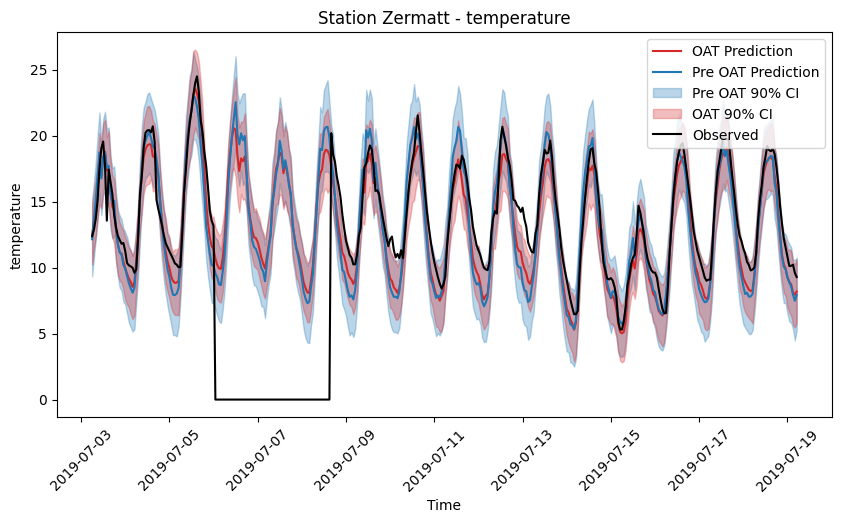

In [135]:
station_idx =80
plt.figure(figsize=(10, 5))

plt.plot(times, mean_pred_station[:,station_idx, var_idx], label='OAT Prediction', color='C3')
plt.plot(times, mean_pred_pre_oat_station[:,station_idx, var_idx], label='Pre OAT Prediction', color='C0')
plt.fill_between(times, np.quantile(prediction_pre_oat_station[:, station_idx, :, var_idx].detach().cpu().numpy(), 0.05, axis=-1),
                    np.quantile(prediction_pre_oat_station[:, station_idx, :, var_idx].detach().cpu().numpy(), 0.95, axis=-1), color='C0', alpha=0.3, label='Pre OAT 90% CI')
plt.fill_between(times, np.quantile(prediction_station[:, station_idx, :, var_idx].detach().cpu().numpy(), 0.05, axis=-1),
                    np.quantile(prediction_station[:, station_idx, :, var_idx].detach().cpu().numpy(), 0.95, axis=-1), color='C3', alpha=0.3, label='OAT 90% CI')

plt.plot(times, obs[:, station_idx, var_idx], label='Observed', color='k')

plt.legend(loc='upper right')
plt.xlabel("Time")
plt.ylabel(predictor.output_var_names[var_idx])
num_eval_stations = test_loader.dataset.station_info['eval'].shape[0]
if station_idx < num_eval_stations:
    plt.title(f"Station {test_loader.dataset.station_info['eval']['station_name'].iloc[station_idx]} - {predictor.output_var_names[var_idx]}")
else:
    plt.title(f"Station {test_loader.dataset.station_info['observed']['station_name'].iloc[station_idx-num_eval_stations]} - {predictor.output_var_names[var_idx]}")
plt.xticks(rotation=45)
plt.show()

# Plot output at different model stages

### Topographic encoder

In [ ]:
with torch.no_grad():
    topo_enc = predictor.model.topographic_encoder(batch['query_data']['topo'])
topo_enc_resh = topo_enc.reshape(batch_size, *mesh_shape[:-1], -1).detach().cpu().numpy()
plt.pcolor(mesh[:, :, 0], mesh[:, :, 1], topo_enc_resh[0, :, :, 0], shading='auto')

### Global Encoder

In [ ]:
with torch.no_grad():
    global_enc = predictor.model.global_encoder(batch['global_data'], batch['query_data'])
global_enc_resh = global_enc.reshape(batch_size, *mesh_shape[:-1], -1).detach().cpu().numpy()
plt.pcolor(mesh[:, :, 0], mesh[:, :, 1], global_enc_resh[0, :, :, 1], shading='auto')

# After first fusion layer

In [ ]:
predictor.eval()
with torch.no_grad():
    cond = batch['global_data']['time_emb'].unsqueeze(1).expand(batch_size, mesh_flattened.shape[0], -1)
    uninformed_token = predictor.model.fusion_layer1(
        global_enc, 
        topo_enc, 
        cond=cond)
uninformed_token_resh = uninformed_token.reshape(batch_size, *mesh_shape[:-1], -1).detach().cpu().numpy()
plt.pcolor(mesh[:, :, 0], mesh[:, :, 1], uninformed_token_resh[0, :, :, 0], shading='auto')
plt.colorbar(label="Uninformed token value")

### Attention bias

In [ ]:
geo_transform = predictor.input_transform.transform_dict['query_data'].transform_dict['geo']
d_geo = torch.abs(geo_transform(center_geo) - geo_transform(query_batch['geo'][0]))[None]
attn_bias = predictor.model.oat_block.decoder.layers[0].self_attn.f_geo(d_geo).detach().cpu()

In [ ]:
attn_bias_mesh = attn_bias.view(*mesh_shape[:-1], -1)

In [ ]:
plt.figure(figsize=(20, 5))
for ihead in range(attn_bias_mesh.shape[-1]):
    plt.subplot(1, attn_bias_mesh.shape[-1], ihead + 1)
    im = plt.pcolor(mesh[:, :, 0], mesh[:, :, 1], attn_bias_mesh[:, :, ihead], shading='auto')
    plt.colorbar(im, label="Attention bias")
    plt.xlabel("Swiss Easting")
    plt.ylabel("Swiss Northing")
    plt.title(f"Attention bias for attention head {ihead}")
    plt.tight_layout()
plt.show()
#plt.tight_layout()

# Geo variables

In [ ]:
# plot d_geo
d_geo_mesh = d_geo.view(*mesh_shape[:-1], -1)
for ivar in range(d_geo_mesh.shape[-1]):
    im = plt.pcolor(mesh[:, :, 0], mesh[:, :, 1], d_geo_mesh[:, :, ivar], shading='auto')
    plt.colorbar(im, label=f"d_geo variable {ivar}")
    plt.xlabel("Swiss Easting")
    plt.ylabel("Swiss Northing")
    plt.title(f"d_geo for variable {ivar}")
    plt.tight_layout()
    plt.show()

In [ ]:
# plot query_batch['geo'][0]
geo_batch_mesh = query_batch['geo'][0].view(*mesh_shape[:-1], -1)

for ivar in range(query_batch['geo'].shape[-1]):
    plt.figure(figsize=(5, 5))
    im = plt.pcolor(mesh[:, :, 0], mesh[:, :, 1], geo_batch_mesh[:, :, ivar], shading='auto')
    plt.colorbar(im, label=f"query geo variable {ivar}")
    plt.xlabel("Swiss Easting")
    plt.ylabel("Swiss Northing")
    plt.title(f"Query geo variable {ivar}")
    plt.tight_layout()
    plt.show()

In [ ]:
query_batch['geo'].shape

In [ ]:
dataset.variable_names